# Ejercicio 1 — Clasificación de sonido ambiental (ESC-50): CNN 2D vs. Transformer A/B

**Inteligencia Artificial y Aprendizaje Profundo II — UCA · TP1**

**Integrantes:** Matías Adell, Agustín Giannice, Facundo Mazzola

**Paper de referencia:** Piczak, K. J. (2015). *ESC: Dataset for Environmental Sound Classification*. Dataset: GitHub `karolpiczak/ESC-50`.

### Índice
0. Consignas
1. Configuración (Colab / local, semilla, versiones, hiperparámetros)
2. Datos: descarga de ESC-50 y split por folds
3. Representación en tiempo y en frecuencia (STFT y mel-spectrogram)
4. Precómputo de los mel-spectrogramas, normalización y SpecAugment
5. Modelos: CNN 2D y Transformer encoder desde cero (Config A y Config B)
6. Entrenamiento con early stopping
7. Evaluación en test: accuracy, F1-macro, matrices de confusión
8. Atención de la Config B sobre el espectrograma
9. Conclusiones (calculadas sobre las métricas)
10. Referencias

## 0. Consignas

1. Cargar el dataset y representar las señales en **tiempo** y **frecuencia** (mel-spectrogram); describir los parámetros de ventana y el **trade-off tiempo-frecuencia**.
2. Implementar tres modelos: una **CNN 2D** sobre el mel-espectrograma y dos configuraciones (**A** y **B**) de un mismo **Transformer encoder desde cero** en PyTorch: tokenización del espectrograma en parches (estilo AST), codificación posicional, atención multi-cabeza, FFN y layer normalization.
3. Entrenar los tres y compararlos en test (accuracy, F1-macro, matriz de confusión), reportando número de parámetros y tiempo de entrenamiento; visualizar los **pesos de atención de la Config B** sobre el espectrograma.

## 1. Configuración

- Detectamos si corremos en **Colab**: solo ahí se instalan dependencias; fuera de Colab se usa la carpeta local `./tp1_local/ej1`.
- `SMOKE_TEST` (por defecto `False`) reduce las épocas (1 época, paciencia 1) para verificar que el notebook corre de punta a punta en CPU. Se activa con la variable de entorno `TP1_SMOKE_TEST=1`, sin editar el notebook.
- En Colab, checkpoints y caches van al disco local del runtime (`/content/TP1_Adell_Giannice_Mazzola/ej1/`) y los WAV a `/content/esc50_data`. Ese disco **se borra al reciclar el runtime**: para conservar los checkpoints hay que comprimir y descargar la carpeta `BASE` antes de cerrar la sesión.
- Semilla fija (`random`, `numpy`, `torch`), dispositivo agnóstico (cuda/cpu) y fp32 (la consigna no exige precisión mixta en este ejercicio).

In [474]:
import os, sys, math, time, random, json, zipfile, urllib.request, platform

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    %pip install -q soundfile

SMOKE_TEST = os.environ.get('TP1_SMOKE_TEST') == '1'

if IN_COLAB:
    BASE = '/content/TP1_Adell_Giannice_Mazzola/ej1'     # disco local de Colab (se pierde al reciclar el runtime)
    DATA_DIR = '/content/esc50_data'                      # WAVs aparte, para no zipearlos con los checkpoints
else:
    BASE = './tp1_local/ej1'
    DATA_DIR = BASE
if SMOKE_TEST:
    BASE = BASE + '/smoke'                     # no mezclar caches del smoke test con los reales
os.makedirs(BASE, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import soundfile as sf
import sklearn
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from IPython.display import display, Markdown

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'IN_COLAB={IN_COLAB} | SMOKE_TEST={SMOKE_TEST} | device={device}')
print('BASE     =', BASE)
print('DATA_DIR =', DATA_DIR)
if device.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

IN_COLAB=False | SMOKE_TEST=False | device=cuda
BASE     = ./tp1_local/ej1
DATA_DIR = ./tp1_local/ej1
GPU: NVIDIA GeForce RTX 3060


In [475]:
# Versiones de las librerías (reproducibilidad)
for name, v in [('python', platform.python_version()), ('torch', torch.__version__),
                ('torchaudio', torchaudio.__version__), ('numpy', np.__version__),
                ('pandas', pd.__version__), ('scikit-learn', sklearn.__version__),
                ('matplotlib', matplotlib.__version__), ('soundfile', sf.__version__)]:
    print(f'{name:>13}: {v}')

# Hiperparámetros de todo el ejercicio
HPARAMS = dict(
    seed=SEED,  # reproducibilidad de la generación aleatoria
    sample_rate=44100, # frecuencia de sampling
    clip_seconds=5.0, # duración de los clips
    n_fft=2048, # tamaño de ventana fft
    hop_length=768,  # salto de la ventana de la fft
    n_mels=128,  # cantidad de bins (bandas) del mel-spectrogram
    folds_train=[1, 2, 3], # que folds de los 5 van a train
    fold_val=4,  # el fold 4 se usa para validación
    fold_test=5, # el fold 5 se usa para testeo
    specaug_freq_mask=30, # ancho maximo del specaugment
    specaug_time_mask=40, # duración maxima del specaugment (frames)
    batch_size=32, 
    max_epochs=1 if SMOKE_TEST else 50,  # máximo de épocas
    patience=1 if SMOKE_TEST else 10,  # early stopping: corta si val no mejora en 10 épocas
    optimizer='AdamW',
    cnn=dict(
        channels=[32, 64, 128, 256], 
        dropout=0.3, 
        lr=1e-3, 
        weight_decay=1e-2,
        cosine=False,
        specaug=True
    ),
    A=dict(
        patch=[128, 18],  # parche (mel × frames): franjas de banda completa -> 16 tokens
        d_model=64,  # dimensión de los embeddings
        n_heads=2,  # cabezas de atención
        n_layers=2,  # bloques del encoder
        d_ff=128,
        dropout=0.0,  # sin dropout
        pre_norm=False,  # post-norm: LayerNorm después del residual
        lr=1e-3, 
        weight_decay=0.0, 
        warmup_epochs=0, 
        cosine=False, 
        specaug=False
        ),
    B=dict(
        patch=[16, 16],  # parche (mel × frames) 2D estilo AST -> 8 × 18 = 144 tokens
        d_model=64,  # dimensión de los embeddings
        n_heads=4,  # cabezas de atención
        n_layers=2,  # bloques del encoder
        d_ff=128,
        dropout=0.1,  # porcentaje de dropout
        pre_norm=True,  # pre-norm: LayerNorm antes de cada subcapa
        lr=1e-3,
        weight_decay=0.05,
        warmup_epochs=1 if SMOKE_TEST else 5,  # épocas de subida lineal del lr
        cosine=True, 
        specaug=True
    )
)
print(json.dumps(HPARAMS, indent=1))

       python: 3.11.16
        torch: 2.14.0+cu130
   torchaudio: 2.11.0+cu130
        numpy: 2.4.6
       pandas: 3.0.6
 scikit-learn: 1.9.1
   matplotlib: 3.11.2
    soundfile: 0.14.0
{
 "seed": 42,
 "sample_rate": 44100,
 "clip_seconds": 5.0,
 "n_fft": 2048,
 "hop_length": 768,
 "n_mels": 128,
 "folds_train": [
  1,
  2,
  3
 ],
 "fold_val": 4,
 "fold_test": 5,
 "specaug_freq_mask": 30,
 "specaug_time_mask": 40,
 "batch_size": 32,
 "max_epochs": 50,
 "patience": 10,
 "optimizer": "AdamW",
 "cnn": {
  "channels": [
   32,
   64,
   128,
   256
  ],
  "dropout": 0.3,
  "lr": 0.001,
  "weight_decay": 0.01,
  "cosine": false,
  "specaug": true
 },
 "A": {
  "patch": [
   128,
   18
  ],
  "d_model": 64,
  "n_heads": 2,
  "n_layers": 2,
  "d_ff": 128,
  "dropout": 0.0,
  "pre_norm": false,
  "lr": 0.001,
  "weight_decay": 0.0,
  "warmup_epochs": 0,
  "cosine": false,
  "specaug": false
 },
 "B": {
  "patch": [
   16,
   16
  ],
  "d_model": 64,
  "n_heads": 4,
  "n_layers": 2,
  "d_ff": 

## 2. Datos: ESC-50

**ESC-50** (Piczak, 2015): clips de 5 s con clases balanceadas, agrupadas en 5 macro-categorías (animales, paisajes naturales y agua, sonidos humanos no verbales, sonidos domésticos, ruidos urbanos). Trae **folds predefinidos**, armados de modo que los fragmentos extraídos de una misma grabación original quedan en el mismo fold (**evita fuga de información entre splits**).

**Split** (consigna): los primeros 3 folds → *train*, un fold → *validación* (early stopping y selección del mejor estado) y el último → *test* (solo se usa una vez, al final)

In [476]:
ESC_URL = 'https://github.com/karolpiczak/ESC-50/archive/master.zip'
ZIP_PATH = os.path.join(DATA_DIR, 'ESC-50-master.zip')
ESC_DIR = os.path.join(DATA_DIR, 'ESC-50-master')

if not os.path.exists(os.path.join(ESC_DIR, 'meta', 'esc50.csv')):
    if not os.path.exists(ZIP_PATH):
        print('Descargando ESC-50 ...'); t0 = time.time()
        urllib.request.urlretrieve(ESC_URL, ZIP_PATH + '.part')
        os.replace(ZIP_PATH + '.part', ZIP_PATH)            # renombrar solo si la descarga terminó
        print(f'  descargado en {time.time() - t0:.0f}s')
    print('Extrayendo ...')
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
print('ESC-50 en', ESC_DIR)

meta = pd.read_csv(os.path.join(ESC_DIR, 'meta', 'esc50.csv'))
CLASSES = meta.drop_duplicates('target').sort_values('target')['category'].tolist()
N_CLASSES = len(CLASSES)
print(f'{len(meta)} clips | {N_CLASSES} clases | folds {sorted(int(f) for f in meta.fold.unique())}')
meta.head()

ESC-50 en ./tp1_local/ej1\ESC-50-master
2000 clips | 50 clases | folds [1, 2, 3, 4, 5]


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [477]:
df = meta.reset_index(drop=True)

split_of = lambda f: 'train' if f in HPARAMS['folds_train'] else ('val' if f == HPARAMS['fold_val'] else 'test')
df['split'] = df.fold.map(split_of)
split_tbl = df.groupby('split').agg(clips=('filename', 'size'), clases=('target', 'nunique'),
                                    folds=('fold', lambda s: sorted(s.unique())))
display(split_tbl)

per_class = meta.groupby('target').size()
fold_of = lambda s: ', '.join(str(f) for f in split_tbl.loc[s, 'folds'])
display(Markdown(
    f'**Dataset (calculado).** ESC-50 tiene **{len(meta)} clips** de {HPARAMS["clip_seconds"]:.0f} s en **{N_CLASSES} clases** '
    f'({per_class.min() if per_class.min() == per_class.max() else f"{per_class.min()}–{per_class.max()}"} clips por clase) '
    f'y **{meta.fold.nunique()} folds**.\n\n'
    f'**Split usado:** train = folds {fold_of("train")} ({split_tbl.loc["train", "clips"]} clips), '
    f'validación = fold {fold_of("val")} ({split_tbl.loc["val", "clips"]} clips), '
    f'test = fold {fold_of("test")} ({split_tbl.loc["test", "clips"]} clips).'
    ))

,clips,clases,folds
split,,,
test,400,50,[5]
train,1200,50,"[1, 2, 3]"
val,400,50,[4]


**Dataset (calculado).** ESC-50 tiene **2000 clips** de 5 s en **50 clases** (40 clips por clase) y **5 folds**.

**Split usado:** train = folds 1, 2, 3 (1200 clips), validación = fold 4 (400 clips), test = fold 5 (400 clips).

## 3. Representación en tiempo y en frecuencia

### 3.1 Carga y resampleo
Leemos cada WAV con `soundfile` (lo convertimos a tensor mono). Por Nyquist, a 44100 Hz se representan frecuencias hasta 22050 Hz, todo el rango audible. Todos los clips se recortan o completan con ceros a exactamente 5 s.

### 3.2 STFT
Un sonido ambiental es **no estacionario** (su contenido espectral cambia en el tiempo), así que una FFT global no alcanza: la **STFT** divide la señal en ventanas cortas, multiplica cada una por una **ventana** $w[n]$ y calcula su FFT:

$$X[m,k] = \sum_{n=0}^{N-1} x[n + mH]\, w[n]\, e^{-j2\pi kn/N}$$

- **`n_fft` ($N$)**: largo de la ventana. Fija la **resolución frecuencial** $\Delta f = f_s / N$ y la **duración** de la ventana $N / f_s$ (cuánto tiempo se "promedia").
- **`hop_length` ($H$)**: desplazamiento entre ventanas. Fija el paso temporal entre frames $\Delta t = H / f_s$; el solape entre ventanas es $1 - H/N$ (con $N = 2048$ y $H = 768$, 62.5 %).

### 3.3 Trade-off tiempo-frecuencia (Gabor)
No se puede tener resolución arbitrariamente buena en ambos dominios (principio de incertidumbre de Gabor, $\Delta t\,\Delta f \geq \tfrac{1}{4\pi}$): una ventana **larga** separa frecuencias cercanas pero "borronea" los transitorios en el tiempo; una ventana **corta** localiza bien los golpes y ataques pero mezcla frecuencias vecinas. Más abajo se compara la misma señal con dos tamaños de ventana.

### 3.4 Escala mel
El oído distingue mucho mejor diferencias de frecuencia en graves que en agudos. La escala mel ($m = 2595\log_{10}(1 + f/700)$) es aproximadamente lineal por debajo de ~500 Hz y logarítmica por encima de ~1 kHz. El **mel-spectrogram** aplica al espectrograma un banco de filtros triangulares espaciados en mel (acá `n_mels = 128`) y luego se pasa a dB. Resultado: una imagen compacta (128 bandas × frames) alineada con la percepción.

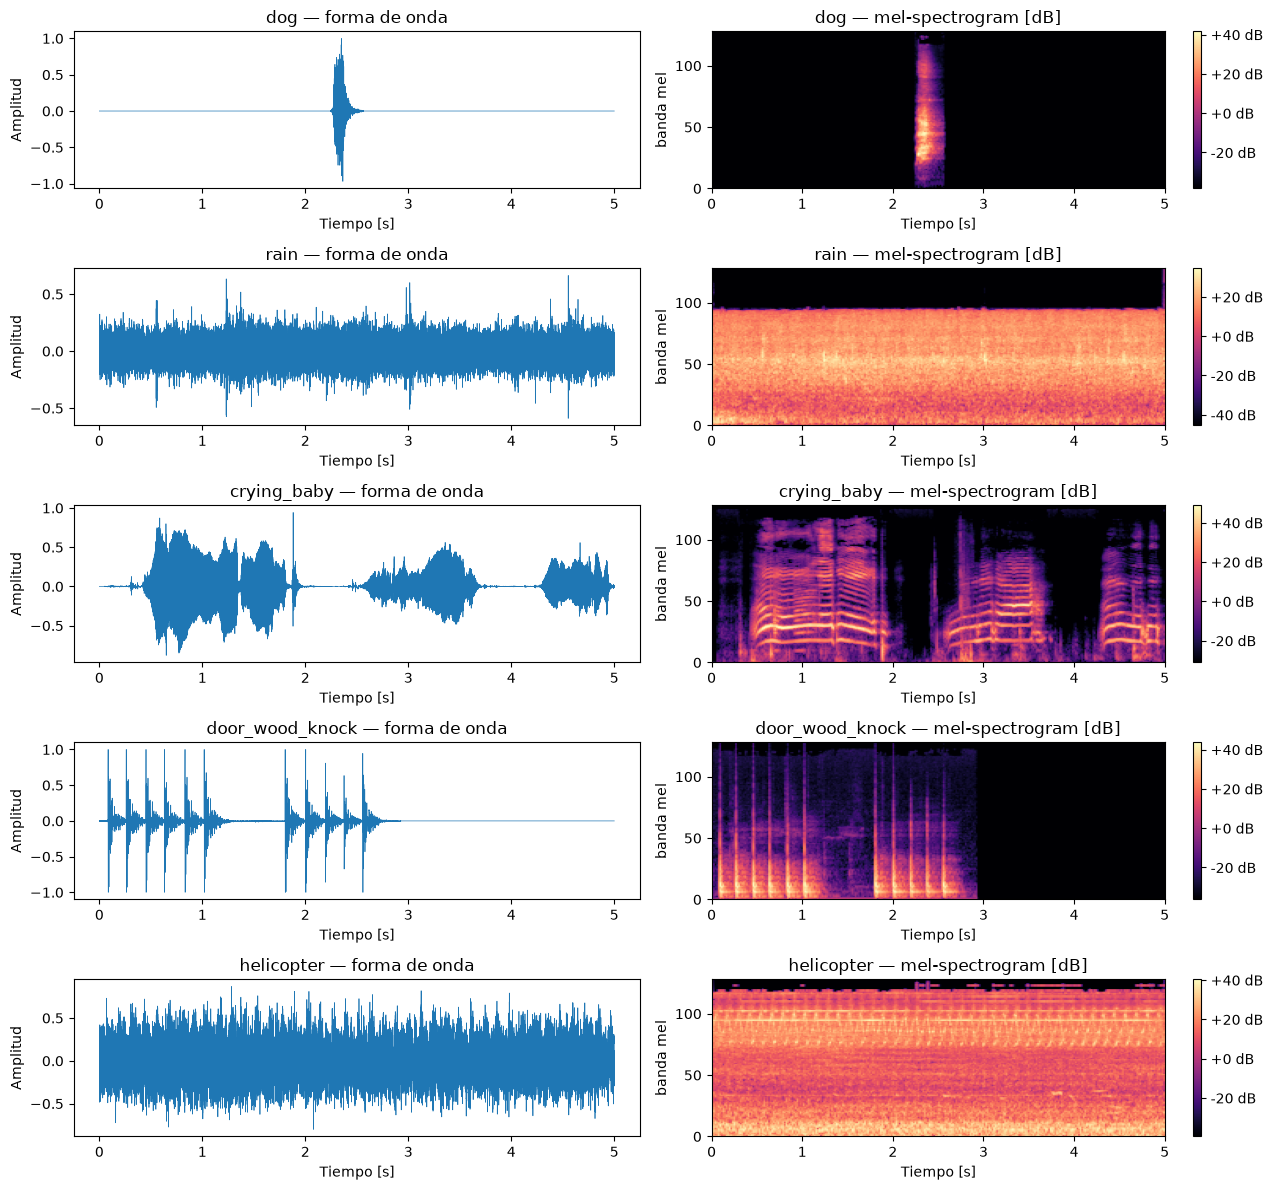

In [478]:
SR = HPARAMS['sample_rate']
N_SAMPLES = int(SR * HPARAMS['clip_seconds'])

def load_wav(filename):
    # soundfile -> tensor mono (1, N) a SR Hz y exactamente 5 s
    x, sr = sf.read(os.path.join(ESC_DIR, 'audio', filename), dtype='float32', always_2d=True)
    assert sr == SR, f'{filename}: {sr} Hz != {SR} Hz'
    x = torch.from_numpy(x.mean(axis=1)).unsqueeze(0)
    return F.pad(x, (0, max(0, N_SAMPLES - x.shape[-1])))[..., :N_SAMPLES]

mel_tf = T.MelSpectrogram(sample_rate=SR, n_fft=HPARAMS['n_fft'], hop_length=HPARAMS['hop_length'],
                          n_mels=HPARAMS['n_mels'], window_fn=torch.hann_window, power=2.0)
to_db = T.AmplitudeToDB(stype='power', top_db=80)

def plot_time(ax, x, title):
    t = np.arange(x.shape[-1]) / SR
    ax.plot(t, x.squeeze().numpy(), lw=0.5); ax.set_title(title)
    ax.set_xlabel('Tiempo [s]'); ax.set_ylabel('Amplitud')

# Un clip por cada clase de ejemplo (una por macro-categoría): dog, rain, crying_baby, door_wood_knock, helicopter
DEMO_CLASSES = [0, 10, 20, 30, 40]
demo = df.drop_duplicates('target').set_index('target').loc[DEMO_CLASSES]
waves = {row.category: load_wav(row.filename) for row in demo.itertuples()}

fig, axes = plt.subplots(len(waves), 2, figsize=(13, 2.4 * len(waves)))
for i, (cat, x) in enumerate(waves.items()):
    plot_time(axes[i, 0], x, f'{cat} — forma de onda')
    m = to_db(mel_tf(x))[0]
    im = axes[i, 1].imshow(m.numpy(), origin='lower', aspect='auto', cmap='magma',
                           extent=[0, HPARAMS['clip_seconds'], 0, HPARAMS['n_mels']])
    axes[i, 1].set_title(f'{cat} — mel-spectrogram [dB]')
    axes[i, 1].set_xlabel('Tiempo [s]'); axes[i, 1].set_ylabel('banda mel')
    fig.colorbar(im, ax=axes[i, 1], format='%+.0f dB')
plt.tight_layout(); plt.show()

fs = 44100 Hz -> Nyquist = 22050 Hz
n_fft = 2048 muestras -> ventana de 46.4 ms | Δf = fs/n_fft = 21.53 Hz
hop   = 768 muestras -> Δt = hop/fs = 17.4 ms | solape = 62 %
Bins de la STFT lineal: 1025 | bandas mel: 128 | frames por clip: 288


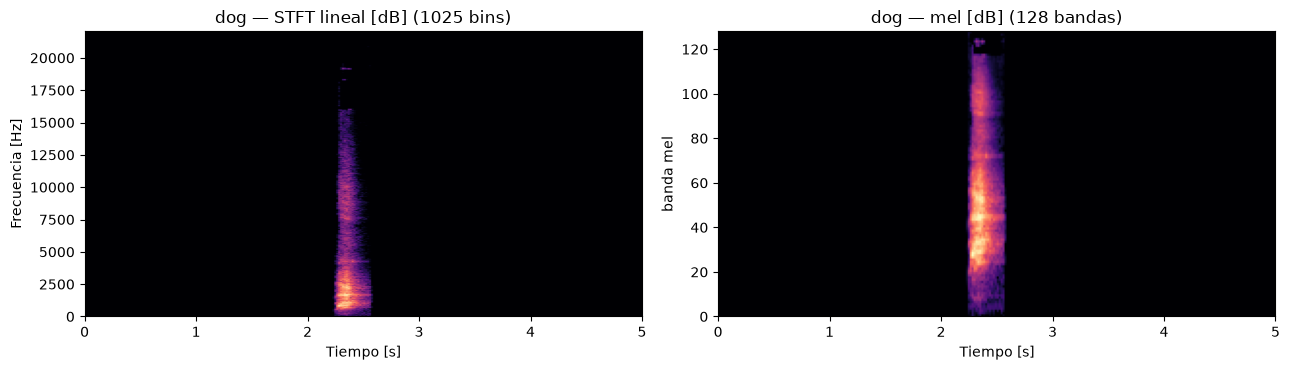

Forma STFT lineal: (1025, 288) | forma mel: (128, 288) -> el mel comprime 8.0x el eje de frecuencia


In [479]:
# Parámetros de ventana y resoluciones resultantes (calculadas, no escritas a mano)
n_fft, hop = HPARAMS['n_fft'], HPARAMS['hop_length']
n_frames = 1 + N_SAMPLES // hop                      # STFT centrada
print(f'fs = {SR} Hz -> Nyquist = {SR / 2:.0f} Hz')
print(f'n_fft = {n_fft} muestras -> ventana de {1000 * n_fft / SR:.1f} ms | Δf = fs/n_fft = {SR / n_fft:.2f} Hz')
print(f'hop   = {hop} muestras -> Δt = hop/fs = {1000 * hop / SR:.1f} ms | solape = {100 * (1 - hop / n_fft):.0f} %')
print(f'Bins de la STFT lineal: {n_fft // 2 + 1} | bandas mel: {HPARAMS["n_mels"]} | frames por clip: {n_frames}')

# STFT lineal vs. mel sobre el mismo clip
cat0, x0 = next(iter(waves.items()))
spec_db = to_db(T.Spectrogram(n_fft=n_fft, hop_length=hop, power=2.0)(x0))[0]
mel_db = to_db(mel_tf(x0))[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].imshow(spec_db.numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 0, SR / 2])
ax[0].set_title(f'{cat0} — STFT lineal [dB] ({spec_db.shape[0]} bins)'); ax[0].set_ylabel('Frecuencia [Hz]')
ax[1].imshow(mel_db.numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 0, HPARAMS['n_mels']])
ax[1].set_title(f'{cat0} — mel [dB] ({mel_db.shape[0]} bandas)'); ax[1].set_ylabel('banda mel')
for a in ax: a.set_xlabel('Tiempo [s]')
plt.tight_layout(); plt.show()
print(f'Forma STFT lineal: {tuple(spec_db.shape)} | forma mel: {tuple(mel_db.shape)} '
      f'-> el mel comprime {spec_db.shape[0] / mel_db.shape[0]:.1f}x el eje de frecuencia')

**Demo del trade-off tiempo-frecuencia.** La misma señal (un sonido con transitorios) con una ventana corta y una larga, con hop = n_fft/4 en ambos casos, en mel (arriba) y en STFT lineal recortada a 0–5 kHz (abajo). Con la ventana corta los golpes quedan como líneas verticales finas, pero la STFT tiene pocos bins (uno cada Δf): en el espectrograma lineal las bandas se ven gruesas y en el mel, en los graves, hay filtros más angostos que Δf que **no contienen ningún bin** y quedan vacíos (franjas horizontales). Con la ventana larga ocurre lo contrario: más detalle en frecuencia, golpes más borrosos.

door_wood_knock | n_fft=  256: ventana=   5.8 ms  Δf=172.27 Hz  Δt(hop)=  1.5 ms  bins=129  filtros mel vacíos=28/128
door_wood_knock | n_fft= 4096: ventana=  92.9 ms  Δf= 10.77 Hz  Δt(hop)= 23.2 ms  bins=2049  filtros mel vacíos=0/128


e:\Programs\miniconda\envs\tp1\Lib\site-packages\torchaudio\functional\functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (129) may be set too low.
  warnings.warn(


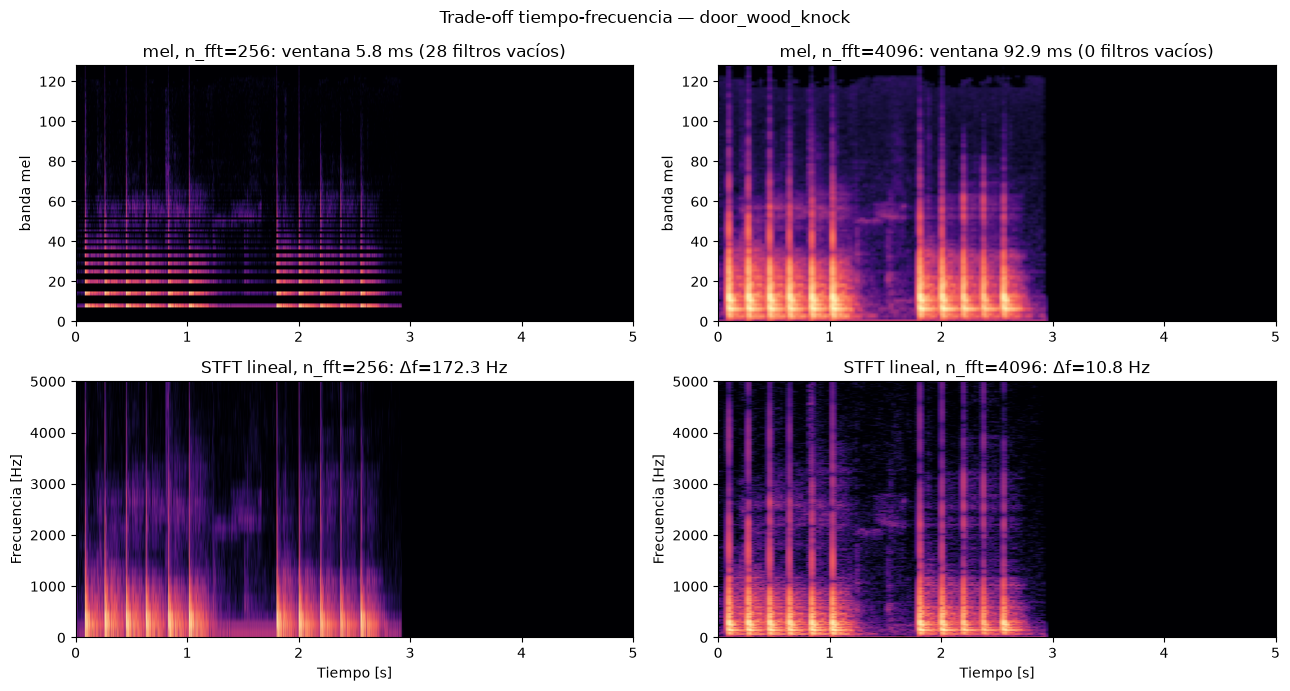

In [480]:
cat_tr = CLASSES[DEMO_CLASSES[3]]         # sonido de golpes (transitorios)
x_tr = waves[cat_tr]
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for j, n in enumerate([256, 4096]):
    mel_n = T.MelSpectrogram(sample_rate=SR, n_fft=n, hop_length=n // 4, n_mels=HPARAMS['n_mels'], power=2.0)
    m = to_db(mel_n(x_tr))[0]
    vacios = int((mel_n.mel_scale.fb.sum(0) == 0).sum())          # filtros mel sin ningún bin de la STFT
    ax[0, j].imshow(m.numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 0, HPARAMS['n_mels']])
    ax[0, j].set_title(f'mel, n_fft={n}: ventana {1000 * n / SR:.1f} ms ({vacios} filtros vacíos)'); ax[0, j].set_ylabel('banda mel')
    s = to_db(T.Spectrogram(n_fft=n, hop_length=n // 4, power=2.0)(x_tr))[0]
    ax[1, j].imshow(s.numpy(), origin='lower', aspect='auto', cmap='magma', extent=[0, 5, 0, SR / 2])
    ax[1, j].set_title(f'STFT lineal, n_fft={n}: Δf={SR / n:.1f} Hz'); ax[1, j].set_ylim(0, 5000)
    ax[1, j].set_xlabel('Tiempo [s]'); ax[1, j].set_ylabel('Frecuencia [Hz]')
    print(f'{cat_tr} | n_fft={n:5d}: ventana={1000 * n / SR:6.1f} ms  Δf={SR / n:6.2f} Hz  '
          f'Δt(hop)={1000 * (n // 4) / SR:5.1f} ms  bins={s.shape[0]}  filtros mel vacíos={vacios}/{HPARAMS["n_mels"]}')
plt.suptitle(f'Trade-off tiempo-frecuencia — {cat_tr}'); plt.tight_layout(); plt.show()

## 4. Precómputo de los mel-spectrogramas, normalización y SpecAugment

La representación es fija, así que se calcula **una sola vez** para todo el dataset y se **cachea en disco** (un tensor `(N, 128, 288)`); el entrenamiento lee directamente el tensor en memoria (en GPU si está disponible), lo que hace cada época muy rápida.

**Normalización:** se estandariza con la **media y el desvío del conjunto de train** (un escalar cada uno), aplicados igual a validación y test para no filtrar información de estos splits.

**SpecAugment** (Park et al., 2019) se aplica *on-the-fly* sobre el mel ya normalizado, **solo en train** y solo para la **CNN** y la **Config B**: `FrequencyMasking(30)` tapa una banda de hasta 30 bandas mel y `TimeMasking(40)` un tramo de hasta 40 frames, con máscaras independientes por ejemplo (`iid_masks=True`). El valor de relleno (0) coincide con la media tras la normalización. La **Config A** se entrena **sin** SpecAugment (sin ninguna regularización).

In [481]:
cache_path = os.path.join(BASE, 'mels.pt')
if os.path.exists(cache_path):
    cache = torch.load(cache_path)
    print('Mel-spectrogramas leídos del cache', cache_path)
else:
    t0 = time.time(); mels = []
    mel_dev, db_dev = mel_tf.to(device), to_db.to(device)
    for i in range(0, len(df), 100):
        wav = torch.cat([load_wav(f) for f in df.filename[i:i + 100]]).to(device)   # (b, N)
        mels.append(db_dev(mel_dev(wav).unsqueeze(1)).squeeze(1).cpu())            # top_db por clip
    cache = dict(mels=torch.cat(mels), filenames=df.filename.tolist())
    torch.save(cache, cache_path)
    mel_tf, to_db = mel_tf.cpu(), to_db.cpu()
    print(f'Mel-spectrogramas calculados en {time.time() - t0:.1f}s y guardados en {cache_path}')
MELS = cache['mels']
print('Tensor de mels:', tuple(MELS.shape), MELS.dtype)

Mel-spectrogramas leídos del cache ./tp1_local/ej1\mels.pt
Tensor de mels: (2000, 128, 288) torch.float32


Normalización con estadísticas de train: media = -11.73 dB, desvío = 21.71 dB
train: X (1200, 1, 128, 288)  clases presentes: 50
  val: X (400, 1, 128, 288)  clases presentes: 50
 test: X (400, 1, 128, 288)  clases presentes: 50


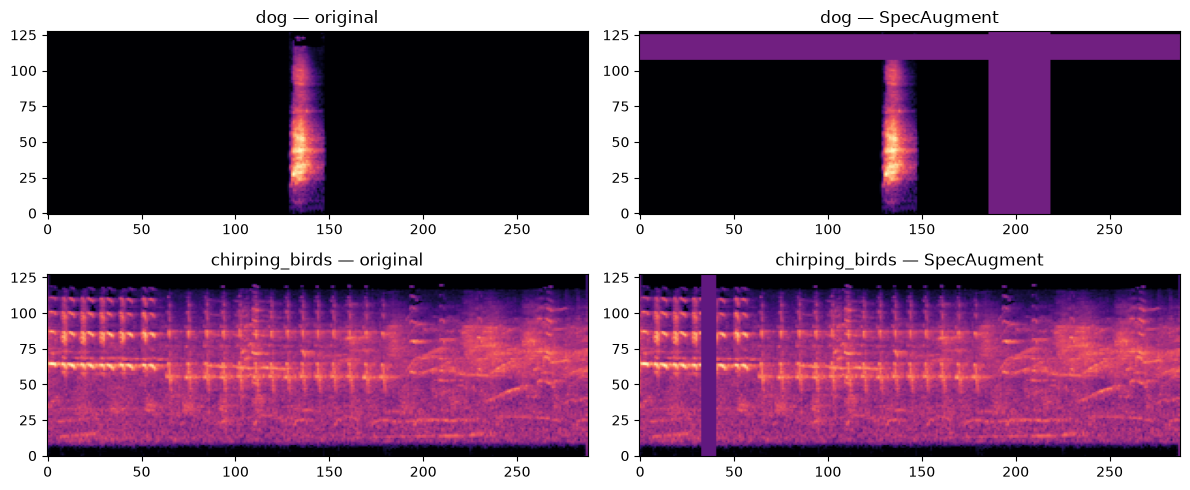

In [482]:
idx = {s: np.where(df.split.values == s)[0] for s in ['train', 'val', 'test']}
labels = torch.tensor(df.target.values)

mu, sd = MELS[idx['train']].mean().item(), MELS[idx['train']].std().item()
print(f'Normalización con estadísticas de train: media = {mu:.2f} dB, desvío = {sd:.2f} dB')

def make_split(s):
    X = ((MELS[idx[s]] - mu) / sd).unsqueeze(1).to(device)        # (N, 1, n_mels, frames)
    return X, labels[idx[s]].to(device)

Xtr, ytr = make_split('train'); Xva, yva = make_split('val'); Xte, yte = make_split('test')
N_MELS, N_FRAMES = Xtr.shape[-2:]
for s, (X, y) in zip(['train', 'val', 'test'], [(Xtr, ytr), (Xva, yva), (Xte, yte)]):
    print(f'{s:>5}: X {tuple(X.shape)}  clases presentes: {y.unique().numel()}')

spec_augment = nn.Sequential(T.FrequencyMasking(HPARAMS['specaug_freq_mask'], iid_masks=True),
                             T.TimeMasking(HPARAMS['specaug_time_mask'], iid_masks=True)).to(device)

# Vista de SpecAugment sobre dos ejemplos de train
set_seed()
aug = spec_augment(Xtr[:2].clone())
fig, ax = plt.subplots(2, 2, figsize=(12, 5))
for i in range(2):
    for j, (m, t) in enumerate([(Xtr[i], 'original'), (aug[i], 'SpecAugment')]):
        ax[i, j].imshow(m[0].cpu().numpy(), origin='lower', aspect='auto', cmap='magma')
        ax[i, j].set_title(f'{CLASSES[ytr[i].item()]} — {t}')
plt.tight_layout(); plt.show()

## 5. Modelos

### 5.1 CNN 2D (baseline)
El mel-spectrogram se trata como una imagen de un canal. Bloques **Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2** con canales crecientes (32, 64, 128, 256): cada bloque duplica los canales y reduce a la mitad tiempo y frecuencia, agrandando el campo receptivo. Al final, **Global Average Pooling** (invariante a la posición exacta del evento), **dropout** y una capa lineal a las 50 clases.

### 5.2 Transformer encoder desde cero
Se adaptan los bloques de las prácticas de la Unidad II (Practica1/Practica4), escritos explícitamente — **no** se usa ninguna de las clases `Transformer*` ni `MultiheadAttention` de `torch.nn`:

- `scaled_dot_product_attention`: $\mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$; devuelve la salida **y los pesos** de atención.
- `MultiHeadAttention`: proyecciones $W_Q, W_K, W_V$, separación en $h$ cabezas $(B, h, L, d_k)$, atención por cabeza, concatenación y proyección de salida $W_O$.
- `PositionwiseFFN`: Linear → ReLU → Linear.
- `EncoderLayer` con flag `pre_norm`:
  - **post-norm** (Transformer original, Config A): en cada subcapa (atención y FFN) se suma la entrada a la salida (conexión residual) y **después** se aplica la LayerNorm.
  - **pre-norm** (Config B): la LayerNorm se aplica **antes** de cada subcapa, y la suma residual queda sin normalizar; además se agrega una LayerNorm final antes de la cabeza.

`SpectrogramTransformer` (una **única clase** parametrizada, estilo AST):
1. **Patching**: el espectrograma $(128 \times T)$ se parte en parches de $p_h \times p_w$ sin solape; si $T$ no es múltiplo de $p_w$ se completa con ceros (= media, tras normalizar) a la derecha.
2. **Proyección lineal** de cada parche aplanado a `d_model` (equivalente a una convolución con kernel = stride = parche).
3. Se antepone un **token [CLS]** aprendido y se suma un **positional embedding 1D aprendido** (como AST); la atención es invariante a permutaciones, así que sin esto se perdería "dónde" está cada parche.
4. $L$ bloques `EncoderLayer`; la salida del [CLS] alimenta la cabeza lineal de clasificación. Opcionalmente devuelve las matrices de atención de cada capa.

### 5.3 Configuraciones A y B
Las dos configuraciones comparten la clase `SpectrogramTransformer` y difieren en la **tokenización** (A: franjas temporales de banda completa → secuencia corta; B: parches 2D estilo AST → secuencia larga) y en la **regularización/estabilización** (A: post-norm, sin dropout, sin weight decay, sin SpecAugment y LR constante; B: pre-norm con LN final, dropout, weight decay, SpecAugment y warmup + coseno). La tabla siguiente se arma directamente desde `HPARAMS`.

In [483]:
#@title Tabla de configuraciones A y B (generada desde HPARAMS)
def cfg_row(c):
    nF, nT = math.ceil(N_MELS / c['patch'][0]), math.ceil(N_FRAMES / c['patch'][1])
    return {
        'Tokenización': f'parches {c["patch"][0]} × {c["patch"][1]} (mel × frames) → {nF} × {nT} = {nF * nT} tokens (+ CLS)',
        'Encoder': f'{c["n_layers"]} capas, d_model {c["d_model"]}, {c["n_heads"]} cabezas, d_ff {c["d_ff"]}',
        'Normalización': 'pre-norm + LN final' if c['pre_norm'] else 'post-norm',
        'Dropout / weight decay': f'{c["dropout"]} / {c["weight_decay"]}',
        'SpecAugment': 'sí' if c['specaug'] else 'no',
        'Learning rate': f'{c["lr"]:g}, ' + (f'warmup {c["warmup_epochs"]} ép. + coseno' if c['cosine'] else 'constante'),
    }

ra, rb = cfg_row(HPARAMS['A']), cfg_row(HPARAMS['B'])
display(Markdown('| | Config A | Config B |\n|---|---|---|\n' +
                 '\n'.join(f'| {k} | {ra[k]} | {rb[k]} |' for k in ra)))

| | Config A | Config B |
|---|---|---|
| Tokenización | parches 128 × 18 (mel × frames) → 1 × 16 = 16 tokens (+ CLS) | parches 16 × 16 (mel × frames) → 8 × 18 = 144 tokens (+ CLS) |
| Encoder | 2 capas, d_model 64, 2 cabezas, d_ff 128 | 2 capas, d_model 64, 4 cabezas, d_ff 128 |
| Normalización | post-norm | pre-norm + LN final |
| Dropout / weight decay | 0.0 / 0.0 | 0.1 / 0.05 |
| SpecAugment | no | sí |
| Learning rate | 0.001, constante | 0.001, warmup 5 ép. + coseno |

El **encoder** (capas, `d_model`, `d_ff`) es idéntico en tamaño en ambas configuraciones (la cantidad de cabezas no cambia el número de parámetros); la diferencia total de parámetros proviene solo de la proyección de parches y del positional embedding, que dependen de la tokenización. El conteo exacto se imprime más abajo.

In [484]:
# ======== Bloques del Transformer construidos DESDE CERO (adaptados de la Unidad II) ========

def scaled_dot_product_attention(Q, K, V, mask=None):
    # Atención escalada por producto punto. Devuelve la salida y los pesos de atención.
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)      # QKᵀ / √d_k
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))
    attn = torch.softmax(scores, dim=-1)                      # pesos de atención (suman 1)
    return attn @ V, attn

class MultiHeadAttention(nn.Module):
    # h cabezas en paralelo: proyecta Q,K,V, aplica atención por cabeza y concatena (Wo).
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.h, self.d_k = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model); self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model); self.Wo = nn.Linear(d_model, d_model)
    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        split = lambda x: x.view(B, -1, self.h, self.d_k).transpose(1, 2)   # (B,h,L,d_k)
        Q, K, V = split(self.Wq(q)), split(self.Wk(k)), split(self.Wv(v))
        if mask is not None: mask = mask.unsqueeze(1)
        out, attn = scaled_dot_product_attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.Wo(out), attn                                          # attn: (B,h,Lq,Lk)

class PositionwiseFFN(nn.Module):
    # Red feed-forward position-wise: Linear -> ReLU -> Linear.
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class EncoderLayer(nn.Module):
    # Self-attention + FFN con residual + LayerNorm; pre_norm elige el orden (pre-norm) o el original (post-norm).
    def __init__(self, d_model, n_heads, d_ff, dropout=0.0, pre_norm=False):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads); self.ffn = PositionwiseFFN(d_model, d_ff, dropout)
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
        self.pre_norm = pre_norm
    def forward(self, x, mask=None):
        if self.pre_norm:
            h = self.n1(x); a, attn = self.attn(h, h, h, mask)
            x = x + self.drop(a)
            x = x + self.drop(self.ffn(self.n2(x)))
        else:
            a, attn = self.attn(x, x, x, mask)
            x = self.n1(x + self.drop(a))
            x = self.n2(x + self.drop(self.ffn(x)))
        return x, attn

In [485]:
class SpectrogramTransformer(nn.Module):
    # Encoder estilo AST: parches del mel -> proyección lineal -> [CLS] + PE aprendido -> L bloques -> cabeza.
    def __init__(self, n_classes, n_mels, n_frames, patch=(16, 16), d_model=64, n_heads=4,
                 n_layers=2, d_ff=128, dropout=0.0, pre_norm=True):
        super().__init__()
        self.ph, self.pw = patch
        self.grid = (math.ceil(n_mels / self.ph), math.ceil(n_frames / self.pw))   # (filas, columnas)
        self.n_tokens = self.grid[0] * self.grid[1]
        self.patch_embed = nn.Linear(self.ph * self.pw, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.zeros(1, 1 + self.n_tokens, d_model))
        nn.init.trunc_normal_(self.cls, std=0.02); nn.init.trunc_normal_(self.pos, std=0.02)
        self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout, pre_norm)
                                     for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model) if pre_norm else nn.Identity()
        self.head = nn.Linear(d_model, n_classes)

    def patchify(self, x):
        # (B,1,F,T) -> (B, n_tokens, ph*pw), recorriendo la grilla fila por fila (frecuencia, luego tiempo)
        F_, T_ = x.shape[-2:]
        x = F.pad(x, (0, self.grid[1] * self.pw - T_, 0, self.grid[0] * self.ph - F_))
        x = x.unfold(2, self.ph, self.ph).unfold(3, self.pw, self.pw)      # (B,1,nF,nT,ph,pw)
        return x.reshape(x.size(0), self.n_tokens, self.ph * self.pw)

    def forward(self, x, return_attn=False):
        z = self.patch_embed(self.patchify(x))
        z = torch.cat([self.cls.expand(z.size(0), -1, -1), z], dim=1) + self.pos
        z = self.drop(z); attns = []
        for layer in self.layers:
            z, a = layer(z); attns.append(a)
        logits = self.head(self.norm(z)[:, 0])                            # representación del [CLS]
        return (logits, attns) if return_attn else logits

def conv_block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                         nn.ReLU(), nn.MaxPool2d(2))

class CNN2D(nn.Module):
    # Bloques Conv-BN-ReLU-MaxPool + Global Average Pooling + dropout + lineal.
    def __init__(self, n_classes, channels=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        chs = [1] + list(channels)
        self.features = nn.Sequential(*[conv_block(a, b) for a, b in zip(chs[:-1], chs[1:])])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(chs[-1], n_classes))
    def forward(self, x): return self.head(self.features(x))

In [486]:
def build_model(name):
    set_seed()                                        # misma inicialización en cada corrida
    if name == 'CNN 2D':
        c = HPARAMS['cnn']
        return CNN2D(N_CLASSES, c['channels'], c['dropout']).to(device)
    c = HPARAMS[name[-1]]
    return SpectrogramTransformer(N_CLASSES, N_MELS, N_FRAMES, tuple(c['patch']), c['d_model'],
                                  c['n_heads'], c['n_layers'], c['d_ff'], c['dropout'],
                                  c['pre_norm']).to(device)

MODEL_NAMES = ['CNN 2D', 'Transformer A', 'Transformer B']
n_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)

rows, tf_rows = [], []
for name in MODEL_NAMES:
    m = build_model(name)
    with torch.no_grad(): out = m(Xtr[:2])
    rows.append({'Modelo': name, 'Parámetros': n_params(m), 'Salida': tuple(out.shape)})
    if name != 'CNN 2D':
        tf_rows.append({'Modelo': name, 'Grilla de parches': m.grid, 'Tokens (+CLS)': f'{m.n_tokens} (+1)',
                        'Patch embed': n_params(m.patch_embed), 'CLS + PE': m.cls.numel() + m.pos.numel(),
                        'Encoder (capas)': n_params(m.layers),
                        'Cabeza + LN': n_params(m.head) + n_params(m.norm), 'Parámetros': n_params(m)})
display(pd.DataFrame(rows).set_index('Modelo'))
tf_df = pd.DataFrame(tf_rows).set_index('Modelo')
display(tf_df)

pA, pB = tf_df.loc['Transformer A'], tf_df.loc['Transformer B']
print(f'Encoder A = {pA["Encoder (capas)"]:,} parámetros | encoder B = {pB["Encoder (capas)"]:,} '
      f'-> {"idénticos" if pA["Encoder (capas)"] == pB["Encoder (capas)"] else "distintos"}')
print(f'Total A = {pA["Parámetros"]:,} vs. total B = {pB["Parámetros"]:,} (ratio A/B = {pA["Parámetros"] / pB["Parámetros"]:.2f}); '
      f'la diferencia ({pA["Parámetros"] - pB["Parámetros"]:+,}) viene de la tokenización: '
      f'patch embed {pA["Patch embed"]:,} vs. {pB["Patch embed"]:,} y PE {pA["CLS + PE"]:,} vs. {pB["CLS + PE"]:,}.')

,Parámetros,Salida
Modelo,,
CNN 2D,401650,"(2, 50)"
Transformer A,218866,"(2, 50)"
Transformer B,96114,"(2, 50)"


,Grilla de parches,Tokens (+CLS),Patch embed,CLS + PE,Encoder (capas),Cabeza + LN,Parámetros
Modelo,,,,,,,
Transformer A,"(1, 16)",16 (+1),147520,1152,66944,3250,218866
Transformer B,"(8, 18)",144 (+1),16448,9344,66944,3378,96114


Encoder A = 66,944 parámetros | encoder B = 66,944 -> idénticos
Total A = 218,866 vs. total B = 96,114 (ratio A/B = 2.28); la diferencia (+122,752) viene de la tokenización: patch embed 147,520 vs. 16,448 y PE 1,152 vs. 9,344.


## 6. Entrenamiento

Loop propio (como en las prácticas de la cátedra), igual para los tres modelos:

- **Optimizador AdamW**, batch 32, pérdida de entropía cruzada, hasta 50 épocas.
- **Early stopping** sobre la **accuracy de validación** (fold 4) con paciencia de 10 épocas; se guarda el **mejor estado** (`state_dict`) y es el que se evalúa en test.
- **Schedule de LR**: constante para la CNN y la Config A; **warmup lineal + decaimiento coseno** (por paso) para la Config B.
- **SpecAugment** en los batches de train de la CNN y la Config B.
- **Tiempo de pared** medido con `time.time()` (sincronizando la GPU), solo del entrenamiento.
- Checkpoint por modelo en `BASE` (mejor estado + historial + tiempo): si ya existe, se carga en lugar de reentrenar (útil si se reinicia el kernel sin perder el runtime). En `SMOKE_TEST` se reentrena siempre.

In [487]:
def lr_lambda_factory(warmup_steps, total_steps, cosine):
    def f(step):
        if step < warmup_steps: return (step + 1) / warmup_steps
        if not cosine: return 1.0
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
    return f

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval()
    return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])

def train_model(name):
    c = HPARAMS['cnn'] if name == 'CNN 2D' else HPARAMS[name[-1]]
    ckpt = os.path.join(BASE, f'ckpt_{name.replace(" ", "_")}.pt')
    model = build_model(name)
    if os.path.exists(ckpt) and not SMOKE_TEST:
        saved = torch.load(ckpt, map_location=device)
        model.load_state_dict(saved['state']); print(f'[{name}] cargado de {ckpt}')
        return model, saved['history'], saved['train_time']

    bs, E = HPARAMS['batch_size'], HPARAMS['max_epochs']
    steps = math.ceil(len(Xtr) / bs)
    opt = torch.optim.AdamW(model.parameters(), lr=c['lr'], weight_decay=c['weight_decay'])
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lr_lambda_factory(c.get('warmup_epochs', 0) * steps, E * steps, c['cosine']))
    lossf = nn.CrossEntropyLoss()
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr']}
    best_acc, best_state, bad = -1.0, None, 0
    set_seed()
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(E):
        model.train(); perm = torch.randperm(len(Xtr), device=device)
        tot_loss, tot_ok = 0.0, 0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]; xb, yb = Xtr[b], ytr[b]
            if c['specaug']: xb = spec_augment(xb)
            logits = model(xb); loss = lossf(logits, yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot_loss += loss.item() * len(b); tot_ok += (logits.argmax(1) == yb).sum().item()
        v_logits = predict(model, Xva)
        v_loss, v_acc = lossf(v_logits, yva).item(), (v_logits.argmax(1) == yva).float().mean().item()
        for k, v in zip(hist, [tot_loss / len(Xtr), tot_ok / len(Xtr), v_loss, v_acc, opt.param_groups[0]['lr']]):
            hist[k].append(v)
        if v_acc > best_acc:
            best_acc, bad = v_acc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % 5 == 0 or bad == 0 or bad >= HPARAMS['patience']:
            print(f'[{name}] época {ep + 1:2d}  train loss {hist["train_loss"][-1]:.3f} acc {hist["train_acc"][-1]:.3f} | '
                  f'val loss {v_loss:.3f} acc {v_acc:.3f}{"  *" if bad == 0 else ""}')
        if bad >= HPARAMS['patience']:
            print(f'[{name}] early stopping en la época {ep + 1}'); break
    if device.type == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    torch.save({'state': best_state, 'history': hist, 'train_time': train_time}, ckpt)
    print(f'[{name}] mejor val acc {best_acc:.3f} (época {int(np.argmax(hist["val_acc"])) + 1}) | '
          f'tiempo {train_time:.1f}s | guardado en {ckpt}')
    return model, hist, train_time

In [488]:
models, histories, train_times = {}, {}, {}
for name in MODEL_NAMES:
    models[name], histories[name], train_times[name] = train_model(name)

[CNN 2D] cargado de ./tp1_local/ej1\ckpt_CNN_2D.pt
[Transformer A] cargado de ./tp1_local/ej1\ckpt_Transformer_A.pt
[Transformer B] cargado de ./tp1_local/ej1\ckpt_Transformer_B.pt


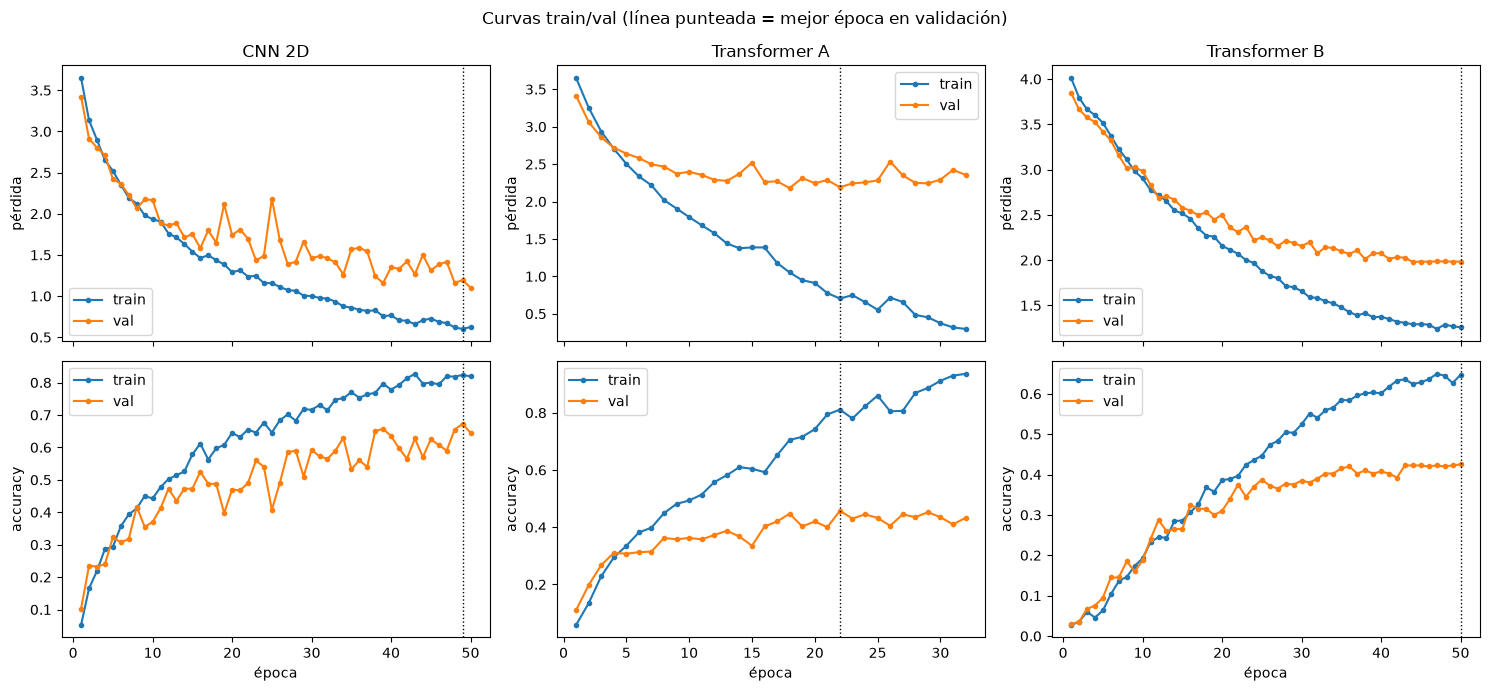

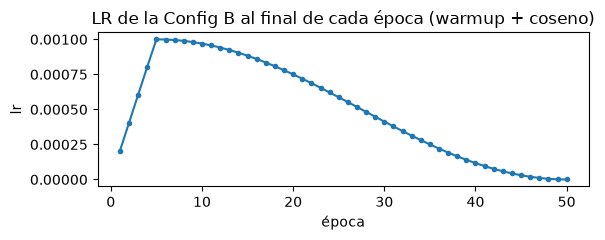

In [489]:
# Curvas de entrenamiento / validación de los tres modelos
fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex='col')
for j, name in enumerate(MODEL_NAMES):
    h = histories[name]; ep = np.arange(1, len(h['train_loss']) + 1); best = int(np.argmax(h['val_acc'])) + 1
    ax[0, j].plot(ep, h['train_loss'], 'o-', ms=3, label='train'); ax[0, j].plot(ep, h['val_loss'], 'o-', ms=3, label='val')
    ax[1, j].plot(ep, h['train_acc'], 'o-', ms=3, label='train'); ax[1, j].plot(ep, h['val_acc'], 'o-', ms=3, label='val')
    for a in ax[:, j]: a.axvline(best, color='k', ls=':', lw=1)
    ax[0, j].set_title(name); ax[0, j].set_ylabel('pérdida'); ax[1, j].set_ylabel('accuracy')
    ax[1, j].set_xlabel('época'); ax[0, j].legend(); ax[1, j].legend()
plt.suptitle('Curvas train/val (línea punteada = mejor época en validación)'); plt.tight_layout(); plt.show()

h = histories['Transformer B']
plt.figure(figsize=(6, 2.5)); plt.plot(np.arange(1, len(h['lr']) + 1), h['lr'], 'o-', ms=3)
plt.title('LR de la Config B al final de cada época (warmup + coseno)'); plt.xlabel('época'); plt.ylabel('lr')
plt.tight_layout(); plt.show()

## 7. Evaluación en test (fold 5)

Con el mejor estado de cada modelo (según validación) calculamos sobre el fold 5, que no se usó en ninguna decisión:
- **Accuracy** y **F1-macro** (promedio no ponderado del F1 de cada clase; con clases balanceadas es cercano a la accuracy, pero penaliza modelos que ignoran clases).
- **Matriz de confusión** 50×50 normalizada por fila (fracción de cada clase real asignada a cada clase predicha).
- **Parámetros** y **tiempo de entrenamiento**, en una tabla comparativa.

,Accuracy test,F1-macro test,Mejor val acc,Train acc (mejor época),Parámetros,Tiempo entrenamiento [s],Épocas corridas,Mejor época
Modelo,,,,,,,,
CNN 2D,0.650,0.631,0.673,0.823,"401,650",75.1,50,49
Transformer A,0.372,0.354,0.457,0.811,"218,866",8.2,32,22
Transformer B,0.393,0.368,0.425,0.647,"96,114",15.4,50,50


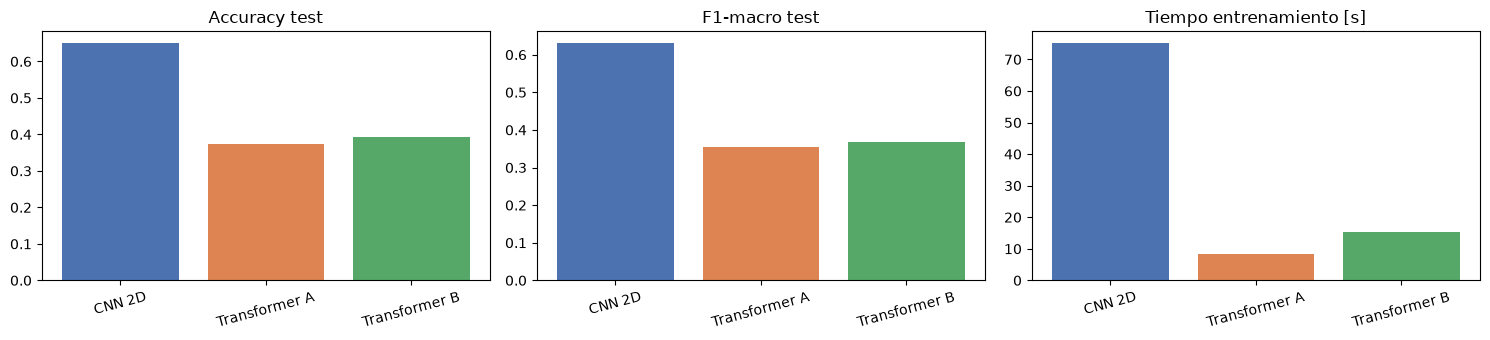

In [490]:
y_true = yte.cpu().numpy()
preds, rows = {}, []
for name in MODEL_NAMES:
    preds[name] = predict(models[name], Xte).argmax(1).cpu().numpy()
    h = histories[name]; best = int(np.argmax(h['val_acc']))
    rows.append({'Modelo': name,
                 'Accuracy test': accuracy_score(y_true, preds[name]),
                 'F1-macro test': f1_score(y_true, preds[name], average='macro'),
                 'Mejor val acc': h['val_acc'][best],
                 'Train acc (mejor época)': h['train_acc'][best],
                 'Parámetros': n_params(models[name]),
                 'Tiempo entrenamiento [s]': train_times[name],
                 'Épocas corridas': len(h['val_acc']), 'Mejor época': best + 1})
results = pd.DataFrame(rows).set_index('Modelo')
results.to_csv(os.path.join(BASE, 'resultados_ej1.csv'))
display(results.style.format({'Accuracy test': '{:.3f}', 'F1-macro test': '{:.3f}', 'Mejor val acc': '{:.3f}',
                              'Train acc (mejor época)': '{:.3f}', 'Parámetros': '{:,}',
                              'Tiempo entrenamiento [s]': '{:.1f}'}))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ['Accuracy test', 'F1-macro test', 'Tiempo entrenamiento [s]']):
    a.bar(results.index, results[col], color=['#4C72B0', '#DD8452', '#55A868']); a.set_title(col)
    a.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

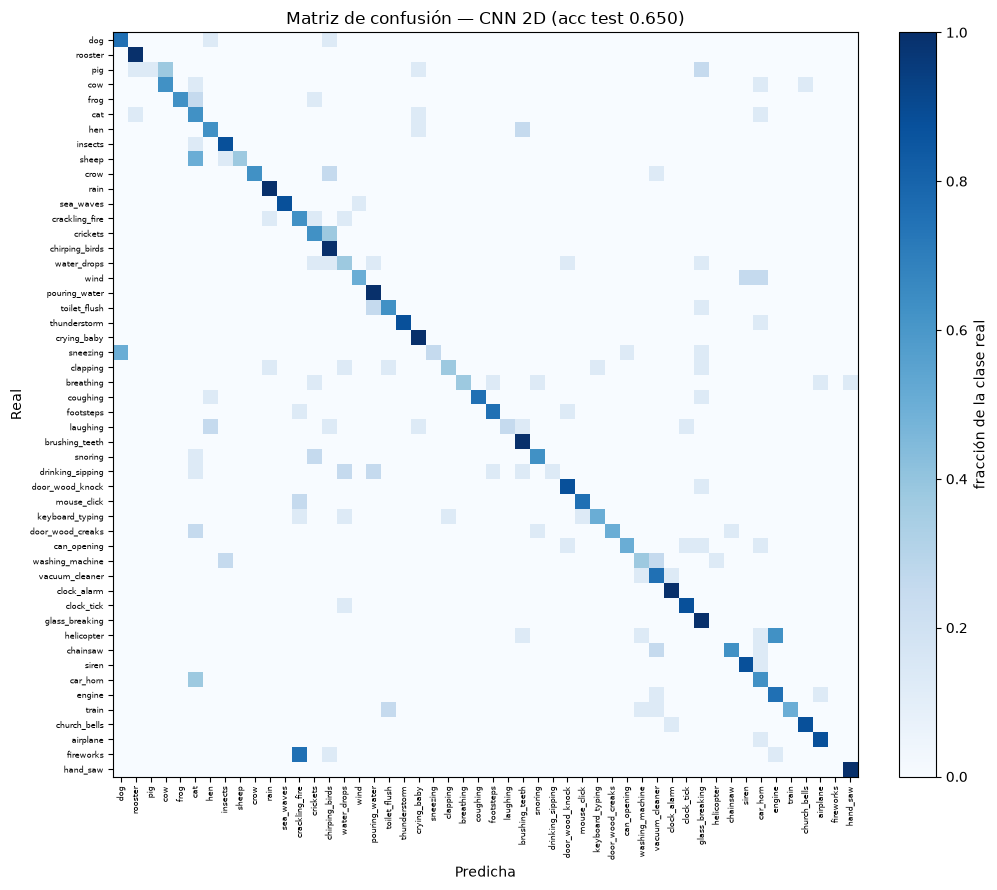

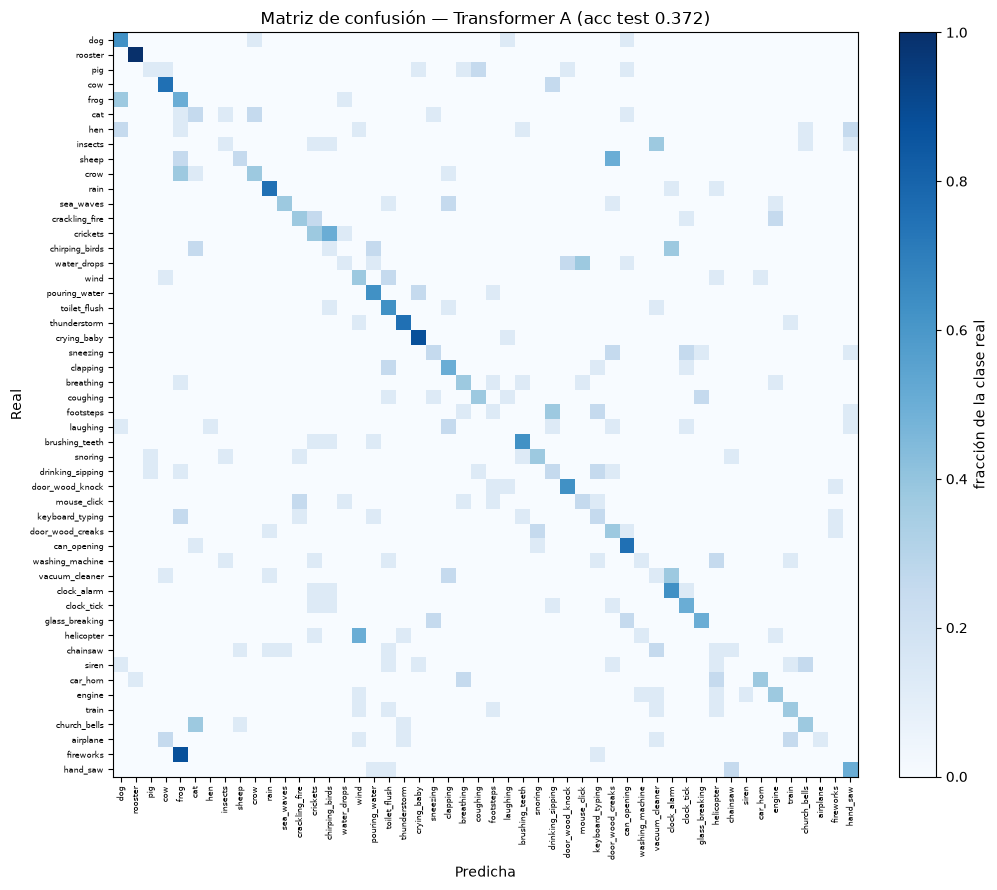

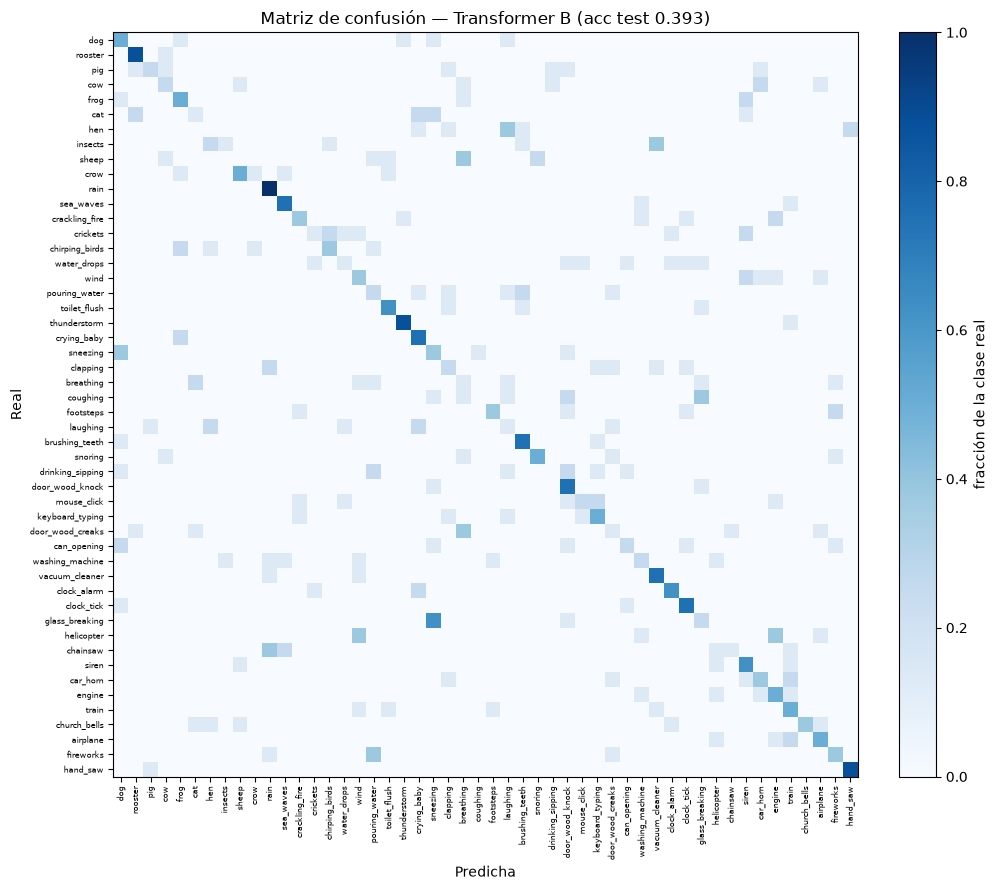

Confusiones más frecuentes en test:


CNN 2D                         Transformer A                          \
         Real        Predicha Clips            Real          Predicha Clips   
1   fireworks  crackling_fire     6       fireworks              frog     7   
2  helicopter          engine     5      helicopter              wind     4   
3    sneezing             dog     4        crickets    chirping_birds     4   
4       sheep             cat     4           sheep  door_wood_creaks     4   
5    car_horn             cat     3    church_bells               cat     3   
6    crickets  chirping_birds     3  vacuum_cleaner       clock_alarm     3   
7         pig             cow     3       footsteps  drinking_sipping     3   
8    laughing             hen     2     water_drops       mouse_click     3   

      Transformer B                        
               Real        Predicha Clips  
1    glass_breaking        sneezing     5  
2              crow           sheep     4  
3  door_wood_creaks       breathing     3  
4          chainsaw            rain     3  
5        helicopter            wind     3  
6          coughing  glass_breaking     3  
7         fireworks   pouring_water     3  
8        helicopter          engine     3

In [491]:
# Matrices de confusión 50x50 (normalizadas por fila) de los tres modelos
for name in MODEL_NAMES:
    cm = confusion_matrix(y_true, preds[name], labels=range(N_CLASSES)).astype(float)
    cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    plt.figure(figsize=(10, 9))
    plt.imshow(cm, cmap='Blues', vmin=0, vmax=1); plt.colorbar(fraction=0.046, label='fracción de la clase real')
    plt.xticks(range(N_CLASSES), CLASSES, rotation=90, fontsize=6); plt.yticks(range(N_CLASSES), CLASSES, fontsize=6)
    plt.xlabel('Predicha'); plt.ylabel('Real')
    plt.title(f'Matriz de confusión — {name} (acc test {results.loc[name, "Accuracy test"]:.3f})')
    plt.tight_layout(); plt.show()

# Pares de clases más confundidos de cada modelo, lado a lado
N_TOP = 8
top_tbl = {}
for name in MODEL_NAMES:
    cm = confusion_matrix(y_true, preds[name], labels=range(N_CLASSES))
    np.fill_diagonal(cm, 0)
    pairs = zip(*np.unravel_index(np.argsort(cm.ravel())[::-1][:N_TOP], cm.shape))
    rows = [{'Real': CLASSES[i], 'Predicha': CLASSES[j], 'Clips': int(cm[i, j])} for i, j in pairs if cm[i, j] > 0]
    rows += [{'Real': '', 'Predicha': '', 'Clips': ''}] * (N_TOP - len(rows))
    top_tbl[name] = pd.DataFrame(rows, index=range(1, N_TOP + 1))
print('Confusiones más frecuentes en test:')
display(pd.concat(top_tbl, axis=1))

## 8. Atención de la Config B sobre el espectrograma

Para interpretar qué regiones del espectrograma usa la Config B para decidir:

1. Tomamos los pesos de atención de la **última capa** desde el token **[CLS]** hacia los parches (fila 0 de la matriz de atención, sin la columna del propio [CLS]) y los **promediamos sobre las cabezas**.
2. El vector resultante (un peso por parche) se lleva a la **grilla de parches** (frecuencia × tiempo), se **sobremuestrea** al tamaño del espectrograma (cada peso cubre su parche de 16 × 16) y se **superpone** al mel-spectrogram.

Se muestran ejemplos de test **bien clasificados**, de clases distintas.

Grilla de parches de B: 8 (frecuencia) x 18 (tiempo) = 144 tokens


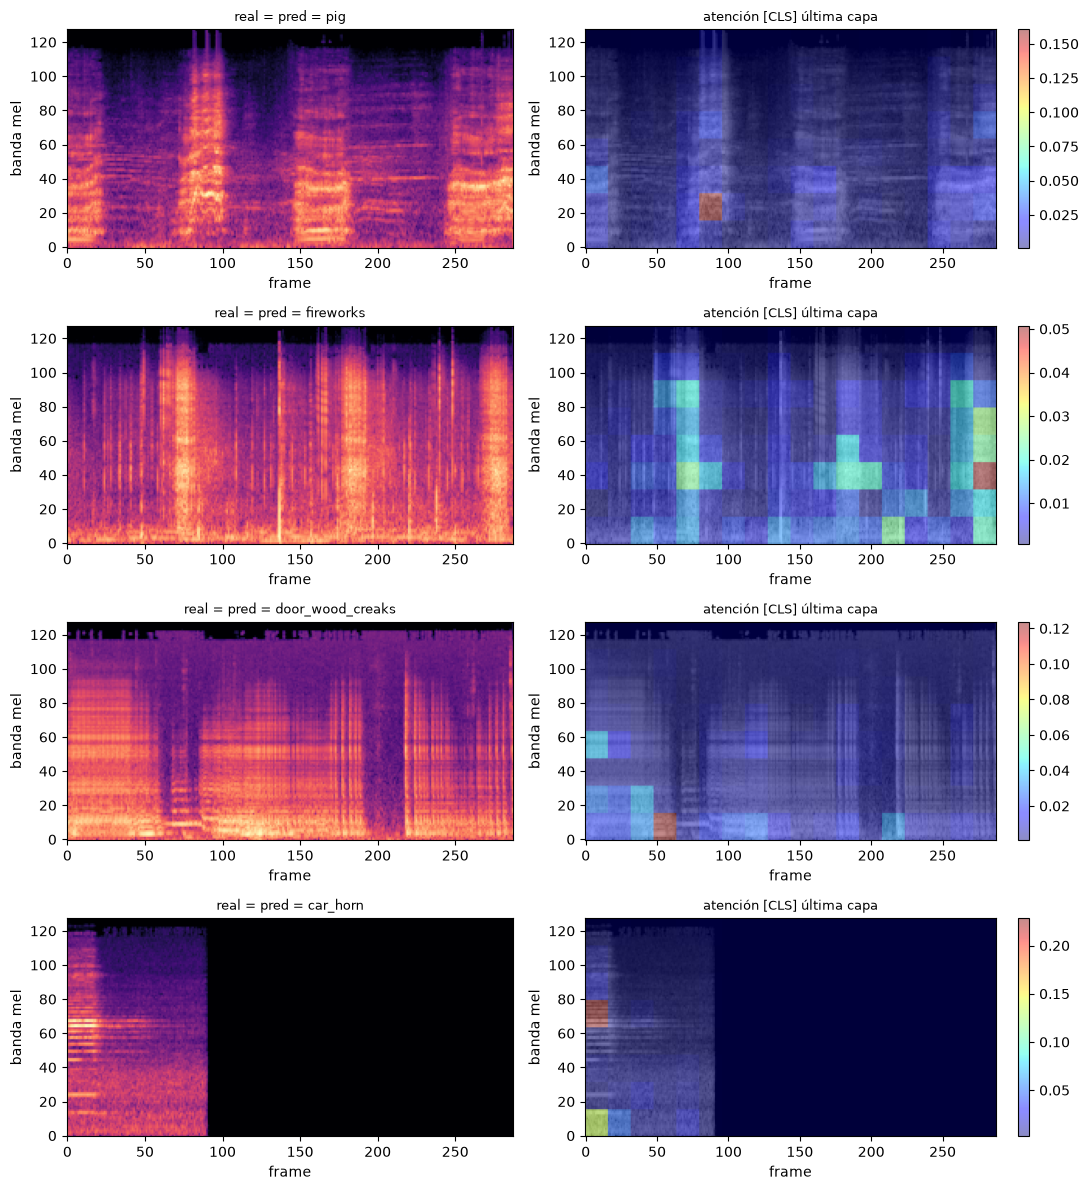

In [492]:
@torch.no_grad()
def cls_attention_maps(model, x):
    # Devuelve la atención [CLS] -> parches de la última capa como mapa del tamaño del espectrograma
    model.eval()
    _, attns = model(x, return_attn=True)                   # lista de (B,h,L,L)
    last = attns[-1].mean(1)[:, 0, 1:]                      # [CLS] -> parches, promedio de cabezas
    nF, nT = model.grid
    g = last.reshape(-1, 1, nF, nT)
    up = F.interpolate(g, scale_factor=(model.ph, model.pw), mode='nearest')
    return up[:, 0, :x.shape[-2], :x.shape[-1]].cpu().numpy()

mB = models['Transformer B']
pB_test = preds['Transformer B']
ok_idx = np.where(pB_test == y_true)[0]
examples = list(dict(zip(y_true[ok_idx][::-1], ok_idx[::-1])).values())[::-1][:4]   # primer acierto de 4 clases distintas

sel = torch.tensor(examples)
last_maps = cls_attention_maps(mB, Xte[sel])
print(f'Grilla de parches de B: {mB.grid[0]} (frecuencia) x {mB.grid[1]} (tiempo) = {mB.n_tokens} tokens')

fig, ax = plt.subplots(len(examples), 2, figsize=(11, 3 * len(examples)))
ax = np.atleast_2d(ax)
for r, i in enumerate(examples):
    spec = Xte[i, 0].cpu().numpy()
    title = f'real = pred = {CLASSES[y_true[i]]}'
    ax[r, 0].imshow(spec, origin='lower', aspect='auto', cmap='magma'); ax[r, 0].set_title(title, fontsize=9)
    ax[r, 1].imshow(spec, origin='lower', aspect='auto', cmap='gray')
    im = ax[r, 1].imshow(last_maps[r], origin='lower', aspect='auto', cmap='jet', alpha=0.45)
    ax[r, 1].set_title('atención [CLS] última capa', fontsize=9); fig.colorbar(im, ax=ax[r, 1], fraction=0.03)
    for a in ax[r]: a.set_xlabel('frame'); a.set_ylabel('banda mel')
plt.tight_layout(); plt.show()

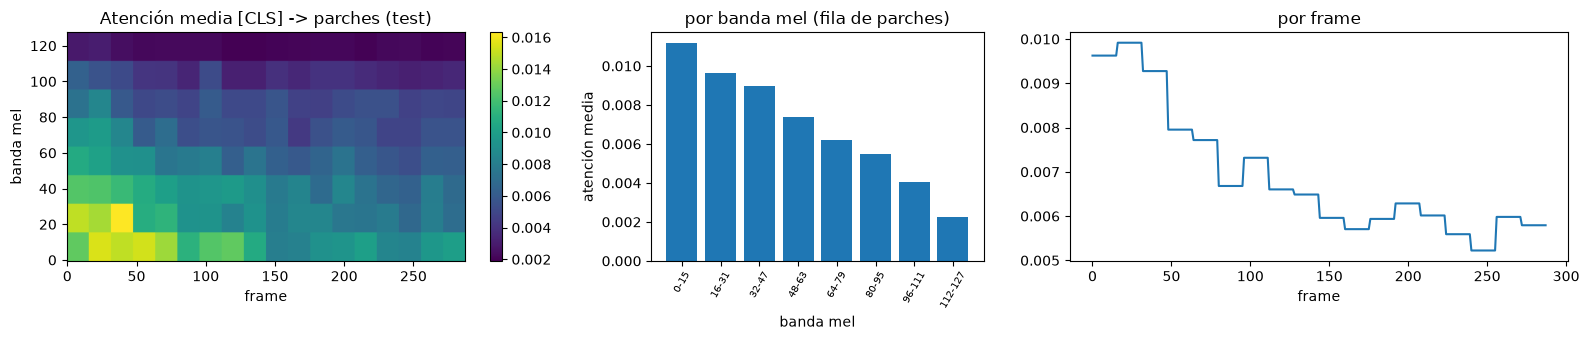

Fracción de la atención media en bandas bajas / medias / altas: 0.48 / 0.33 / 0.19


In [493]:
# Atención promedio del [CLS] (última capa) sobre todo el test: ¿qué bandas y qué tramos mira B en general?
last_all = np.concatenate([cls_attention_maps(mB, Xte[i:i + 64]) for i in range(0, len(Xte), 64)])
mean_map = last_all.mean(0)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5), gridspec_kw={'width_ratios': [3, 2, 3]})
im = ax[0].imshow(mean_map, origin='lower', aspect='auto', cmap='viridis'); fig.colorbar(im, ax=ax[0])
ax[0].set_title('Atención media [CLS] -> parches (test)'); ax[0].set_xlabel('frame'); ax[0].set_ylabel('banda mel')
ph = mB.ph                                                  # bandas mel por fila de parches
rows = mean_map.mean(1).reshape(-1, ph).mean(1)             # una barra por fila de parches
ax[1].bar(np.arange(len(rows)), rows, tick_label=[f'{k * ph}-{(k + 1) * ph - 1}' for k in range(len(rows))])
ax[1].set_title('por banda mel (fila de parches)'); ax[1].set_xlabel('banda mel'); ax[1].set_ylabel('atención media')
ax[1].tick_params(axis='x', labelrotation=60, labelsize=7)
ax[2].plot(mean_map.mean(0)); ax[2].set_title('por frame'); ax[2].set_xlabel('frame')
plt.tight_layout(); plt.show()
band = mean_map.mean(1); third = N_MELS // 3
print(f'Fracción de la atención media en bandas bajas / medias / altas: '
      f'{band[:third].sum() / band.sum():.2f} / {band[third:2 * third].sum() / band.sum():.2f} / {band[2 * third:].sum() / band.sum():.2f}')

## 9. Conclusiones

ranking en test, efecto de la tokenización y la regularización (A vs. B), eficiencia en parámetros y tiempo, sobreajuste (brecha train–validación en la mejor época).

In [494]:
r = results
rank = r.sort_values('Accuracy test', ascending=False)
gap = lambda x: x['Train acc (mejor época)'] - x['Mejor val acc']
out = ['**Ranking por accuracy en test**\n',
       '| Modelo | Accuracy test | F1-macro test | Parámetros | Tiempo [s] |',
       '|---|---|---|---|---|']
for name, row in rank.iterrows():
    out.append(f'| {name} | {row["Accuracy test"]:.3f} | {row["F1-macro test"]:.3f} | '
               f'{int(row["Parámetros"]):,} | {row["Tiempo entrenamiento [s]"]:.1f} |')
out.append('')
A, B, C = r.loc['Transformer A'], r.loc['Transformer B'], r.loc['CNN 2D']
d_acc, d_f1 = B['Accuracy test'] - A['Accuracy test'], B['F1-macro test'] - A['F1-macro test']
out.append('**A vs. B** (mismo encoder, distinta tokenización y regularización)\n')
out.append(f'- B {"supera" if d_acc > 0 else ("empata con" if d_acc == 0 else "queda por debajo de")} A por '
           f'{100 * d_acc:+.1f} pp de accuracy y {100 * d_f1:+.1f} pp de F1-macro.')
out.append(f'- Brecha train-val en la mejor época: A {100 * gap(A):+.1f} pp vs. B {100 * gap(B):+.1f} pp '
           f'→ {"la brecha es mayor en A" if gap(A) > gap(B) else "la brecha es mayor o igual en B"} '
           f'(A no tiene ninguna regularización; B usa dropout, weight decay y SpecAugment).')
out.append(f'- Tokens: A = {models["Transformer A"].n_tokens}, B = {models["Transformer B"].n_tokens} '
           f'({models["Transformer B"].n_tokens / models["Transformer A"].n_tokens:.1f}x más largos en B); '
           f'tiempo de entrenamiento B/A = {B["Tiempo entrenamiento [s]"] / A["Tiempo entrenamiento [s]"]:.2f}x.')

best_tf = 'Transformer B' if B['Accuracy test'] >= A['Accuracy test'] else 'Transformer A'
T_ = r.loc[best_tf]
d_cnn = C['Accuracy test'] - T_['Accuracy test']
out.append(f'\n**CNN 2D vs. mejor Transformer ({best_tf})**\n')
out.append(f'- Accuracy {C["Accuracy test"]:.3f} vs. {T_["Accuracy test"]:.3f} → diferencia CNN − Transformer = {100 * d_cnn:+.1f} pp '
           f'({"gana la CNN" if d_cnn > 0 else ("empate" if d_cnn == 0 else f"gana {best_tf}")}).')
out.append(f'- Parámetros CNN/{best_tf} = {C["Parámetros"] / T_["Parámetros"]:.2f}x; '
           f'tiempo CNN/{best_tf} = {C["Tiempo entrenamiento [s]"] / T_["Tiempo entrenamiento [s]"]:.2f}x.')
if SMOKE_TEST:
    out.append('\n*[SMOKE_TEST] Métricas tras 1 época de entrenamiento: solo validan que el pipeline corre, no son interpretables.*')
display(Markdown('\n'.join(out)))

**Ranking por accuracy en test**

| Modelo | Accuracy test | F1-macro test | Parámetros | Tiempo [s] |
|---|---|---|---|---|
| CNN 2D | 0.650 | 0.631 | 401,650 | 75.1 |
| Transformer B | 0.393 | 0.368 | 96,114 | 15.4 |
| Transformer A | 0.372 | 0.354 | 218,866 | 8.2 |

**A vs. B** (mismo encoder, distinta tokenización y regularización)

- B supera A por +2.0 pp de accuracy y +1.4 pp de F1-macro.
- Brecha train-val en la mejor época: A +35.3 pp vs. B +22.2 pp → la brecha es mayor en A (A no tiene ninguna regularización; B usa dropout, weight decay y SpecAugment).
- Tokens: A = 16, B = 144 (9.0x más largos en B); tiempo de entrenamiento B/A = 1.87x.

**CNN 2D vs. mejor Transformer (Transformer B)**

- Accuracy 0.650 vs. 0.393 → diferencia CNN − Transformer = +25.8 pp (gana la CNN).
- Parámetros CNN/Transformer B = 4.18x; tiempo CNN/Transformer B = 4.88x.

In [495]:
#@title Cómo leer estos resultados (texto generado desde las métricas)
n_train = len(Xtr)
cnn_acc, tf_acc = C['Accuracy test'], T_['Accuracy test']
lines = []

if d_cnn > 0:
    lines.append(f'**CNN vs. Transformers.** Con {n_train} clips de entrenamiento, la CNN 2D ({cnn_acc:.1%}) supera a {best_tf} ({tf_acc:.1%}) '
                 f'por {100 * d_cnn:.1f} pp. Es consistente con que los Transformers entrenados desde cero no tienen el sesgo inductivo '
                 f'de localidad de las convoluciones y dependen más de la regularización y de la cantidad de datos.')
elif d_cnn < 0:
    lines.append(f'**CNN vs. Transformers.** {best_tf} ({tf_acc:.1%}) supera a la CNN 2D ({cnn_acc:.1%}) por {-100 * d_cnn:.1f} pp aun sin '
                 f'preentrenamiento: con {n_train} clips, la tokenización en parches y la regularización compensan la falta de sesgo inductivo.')
else:
    lines.append(f'**CNN vs. Transformers.** La CNN 2D y {best_tf} empatan en accuracy ({cnn_acc:.1%}).')

if d_acc > 0:
    lines.append(f'**A vs. B.** B mejora a A en {100 * d_acc:.1f} pp: con un encoder del mismo tamaño, la tokenización en parches 2D '
                 f'({models["Transformer B"].n_tokens} tokens vs. {models["Transformer A"].n_tokens}) y el paquete de regularización/estabilización '
                 f'(pre-norm, warmup, dropout, SpecAugment) ayudan. Sin ablación no se puede separar el aporte de cada factor.')
elif d_acc < 0:
    lines.append(f'**A vs. B.** A supera a B por {-100 * d_acc:.1f} pp: en este setup la secuencia más larga y la regularización de B no '
                 f'compensaron (posibles causas: pocos datos y épocas, o regularización excesiva). Sin ablación no se puede separar el aporte de cada factor.')
else:
    lines.append('**A vs. B.** A y B empatan en accuracy en test.')

lines.append(f'**Sobreajuste.** Brecha train–validación en la mejor época: A {100 * gap(A):+.1f} pp, B {100 * gap(B):+.1f} pp, CNN {100 * gap(C):+.1f} pp. '
             f'La accuracy de train de B y de la CNN se mide con SpecAugment, así que su brecha no es directamente comparable con la de A.')
lines.append('Los modelos tipo AST alcanzan su mejor desempeño con preentrenamiento (AudioSet/ImageNet), fuera del alcance de este ejercicio.')
if SMOKE_TEST:
    lines.append('*[SMOKE_TEST] Solo 1 época de entrenamiento: estas frases solo validan que la celda corre.*')
display(Markdown('\n\n'.join(lines)))

**CNN vs. Transformers.** Con 1200 clips de entrenamiento, la CNN 2D (65.0%) supera a Transformer B (39.2%) por 25.8 pp. Es consistente con que los Transformers entrenados desde cero no tienen el sesgo inductivo de localidad de las convoluciones y dependen más de la regularización y de la cantidad de datos.

**A vs. B.** B mejora a A en 2.0 pp: con un encoder del mismo tamaño, la tokenización en parches 2D (144 tokens vs. 16) y el paquete de regularización/estabilización (pre-norm, warmup, dropout, SpecAugment) ayudan. Sin ablación no se puede separar el aporte de cada factor.

**Sobreajuste.** Brecha train–validación en la mejor época: A +35.3 pp, B +22.2 pp, CNN +15.1 pp. La accuracy de train de B y de la CNN se mide con SpecAugment, así que su brecha no es directamente comparable con la de A.

Los modelos tipo AST alcanzan su mejor desempeño con preentrenamiento (AudioSet/ImageNet), fuera del alcance de este ejercicio.

## 10. Referencias

- Piczak, K. J. (2015). *ESC: Dataset for Environmental Sound Classification*. ACM Multimedia. https://github.com/karolpiczak/ESC-50
- Gong, Y., Chung, Y.-A., & Glass, J. (2021). *AST: Audio Spectrogram Transformer*. arXiv:2104.01778.
- Vaswani, A. et al. (2017). *Attention Is All You Need*. arXiv:1706.03762.
- Dosovitskiy, A. et al. (2021). *An Image Is Worth 16x16 Words: Transformers for Image Recognition at Scale* (ViT). arXiv:2010.11929.
- Park, D. S. et al. (2019). *SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition*. arXiv:1904.08779.